# Validating the WHACS wave hindcast with satellites, from the cloud

WHACS (BoM-CSIRO, WAVEWATCH III forced by ERA5) is served as a Zarr store with the
partitions 0-3 of Hs, Tp, direction and spread, hourly 2020-2023, on its global SMC grid.
Here its total Hs at one node is compared with the **altimeters** (IMOS store, one value
per pass within 50 km) and with **SWOT KaRIn** (pixels within 5 km), collocated in time
(nearest hour), with bias, RMSE, scatter index and correlation (satellite = reference).

Requirements: `bluemath-tk` (with `bluemath_tk.waves.altimetry`), `xarray`, `zarr>=3`, `fsspec`, `aiohttp`, `matplotlib`, `cartopy`. The stores are read over HTTP: only the chunks needed are downloaded.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from bluemath_tk.core.metrics import compute_metrics
from bluemath_tk.waves.altimetry import open_altimeter, altimeter_near, altimeter_passes, collocate

# Public GeoOcean Zarr stores. On the GeoOcean cluster use "http://geocean01.sci.unican.es/zarr" (faster).
BASE = "https://geoocean.unican.es/zarr"
IMOS_URL = f"{BASE}/IMOS/imos_altimeter_dm00.zarr"
SWOT_URL = f"{BASE}/SWOT/swot_karin_windwave.zarr"
WHACS_URL = f"{BASE}/CSIRO/whacs_global_smc_1h_2020_2023.zarr"

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

LON, LAT = -3.8, 43.7  # Cantabrian Sea, ~20 km off Santander

PERIOD = slice("2023-01-01", "2023-12-31")  # SWOT overlaps WHACS from 2023-07 (science orbit)

In [2]:
whacs = xr.open_zarr(WHACS_URL)
print(whacs.attrs["summary"], "\n\n", whacs.attrs["usage"])
whacs

Partitions 0-3 of the WHACS hindcast (WAVEWATCH III v6.07 forced by ERA5, BoM and CSIRO): significant wave height phs0-3, peak period ptp0-3, mean direction pdir0-3 and directional spread pspr0-3, hourly 2020-2023, on the global SMC grid (2,541,220 sea points, ~25 km offshore to ~7 km at the coast). Partition 0 is the wind sea. 

 Dimensions (time, seapoint) with longitude and latitude per seapoint: find the nearest seapoint, then read its series (chunks of 372 hours x 11,551 points). Total Hs of the four partitions is sqrt(phs0^2 + phs1^2 + phs2^2 + phs3^2) (energy beyond partition 3 is not included). Values decode from int16 as in the files.


<xarray.Dataset> Size: 11TB
Dimensions:    (time: 35064, seapoint: 2541220)
Coordinates:
  * time       (time) datetime64[ns] 281kB 2020-01-01 ... 2023-12-31T23:00:00
  * seapoint   (seapoint) int32 10MB 0 1 2 3 ... 2541216 2541217 2541218 2541219
    latitude   (seapoint) float32 10MB dask.array<chunksize=(2541220,), meta=np.ndarray>
    longitude  (seapoint) float32 10MB dask.array<chunksize=(2541220,), meta=np.ndarray>
Data variables: (12/16)
    pdir0      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    pdir1      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    pdir2      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    pdir3      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    phs0       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    phs1       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    ...         ...
    pspr2      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    pspr3      (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    ptp0       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    ptp1       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    ptp2       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
    ptp3       (time, seapoint) float64 713GB dask.array<chunksize=(372, 11551), meta=np.ndarray>
Attributes: (12/14)
    title:                WHACS wave hindcast: wave partitions (Hs, Tp, direc...
    summary:              Partitions 0-3 of the WHACS hindcast (WAVEWATCH III...
    usage:                Dimensions (time, seapoint) with longitude and lati...
    source:               WHACS (Wave Hindcast for the Australian Climate Ser...
    source_url:           https://data-cbr.csiro.au/thredds5/catalog/catch_all/
    references:           Wave Hindcast for the Australian Climate Service (W...
    ...                   ...
    creator_name:         GeoOcean, Universidad de Cantabria
    creator_url:          https://geoocean.unican.es
    time_coverage_start:  2020-01-01 00:00:00
    time_coverage_end:    2023-12-31 23:00:00
    date_modified:        2026-10-27T16:47:15Z
    Conventions:          CF-1.7

## Hindcast at the nearest node

The SMC grid is unstructured (`seapoint`): find the nearest sea point, then read its series.
Total Hs from the partitions is sqrt(phs0² + phs1² + phs2² + phs3²) (energy beyond partition 3,
usually small, is not included).

In [3]:
lon_ = (whacs.longitude.values + 180) % 360 - 180
lat_ = whacs.latitude.values
d = np.hypot((lon_ - LON) * np.cos(np.deg2rad(LAT)), lat_ - LAT) * 111.2
node = int(np.argmin(d))
print(f"nearest node {node}: ({lon_[node]:.3f}, {lat_[node]:.3f}), {d[node]:.1f} km away")

parts = whacs[["phs0", "phs1", "phs2", "phs3"]].isel(seapoint=node).sel(time=PERIOD).load()
energy = sum(parts[v].fillna(0) ** 2 for v in parts.data_vars)
hs = np.sqrt(energy).where(parts.to_array().notnull().any("variable"))
hindcast = hs.to_dataframe(name="hs")[["hs"]]
hindcast.describe().T

nearest node 2297351: (-3.812, 43.688), 1.7 km away


,count,mean,std,min,25%,50%,75%,max
hs,8760.0,1.858154,1.217512,0.1,1.025461,1.579765,2.262,9.062


## Altimeters (IMOS)

In [4]:
imos = open_altimeter(IMOS_URL)
alt = altimeter_passes(altimeter_near(imos, LON, LAT, radius_km=50, time=PERIOD, min_depth=20))
alt_pairs = collocate(hindcast, alt)
print(f"{len(alt_pairs)} altimeter passes collocated")
alt_metrics = compute_metrics(alt_pairs.sat_hs, alt_pairs.hs, ["bias", "rmse", "si", "r", "slope"])
alt_metrics

279 altimeter passes collocated


{'n': 279,
 'bias': -0.14475220855288887,
 'rmse': 0.35742081790597496,
 'si': 0.1329876978373028,
 'r': 0.9771774923375968,
 'slope': 0.8688932973936507}

## SWOT KaRIn

In [5]:
swot = open_altimeter(SWOT_URL)
kar = altimeter_passes(altimeter_near(swot, LON, LAT, radius_km=5, time=PERIOD, min_dist2coast=2))
kar_pairs = collocate(hindcast, kar)
print(f"{len(kar_pairs)} SWOT passes collocated")
kar_metrics = compute_metrics(kar_pairs.sat_hs, kar_pairs.hs, ["bias", "rmse", "si", "r", "slope"])
pd.DataFrame({"altimeters": alt_metrics, "SWOT KaRIn": kar_metrics}).round(3)

26 SWOT passes collocated


,altimeters,SWOT KaRIn
n,279.000,26.000
bias,-0.145,-0.283
rmse,0.357,0.500
si,0.133,0.168
r,0.977,0.936
slope,0.869,0.840


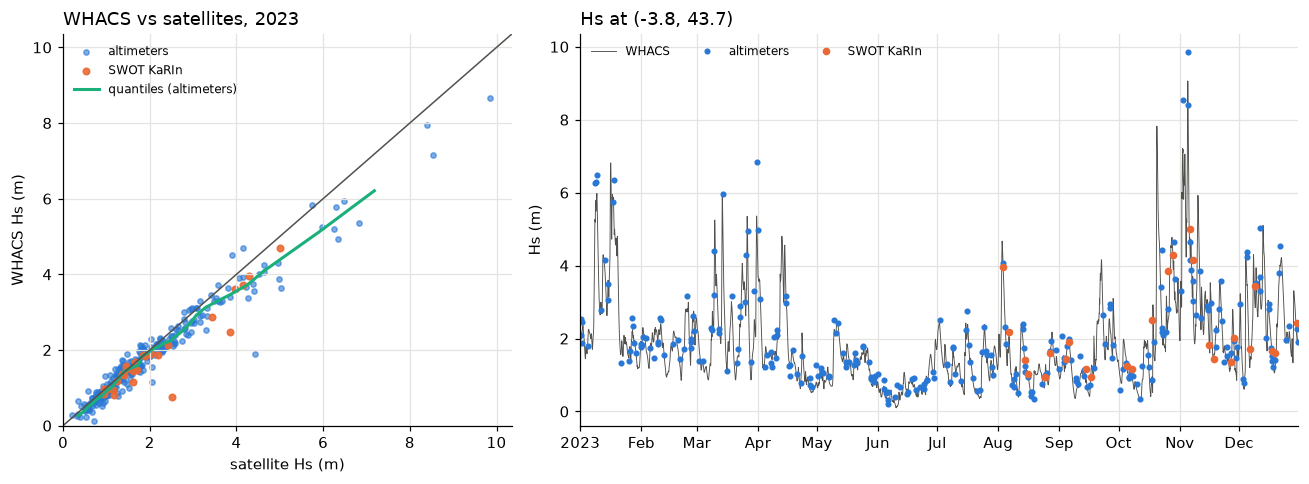

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.scatter(alt_pairs.sat_hs, alt_pairs.hs, s=12, color=BLUE, alpha=0.6, label="altimeters")
ax.scatter(kar_pairs.sat_hs, kar_pairs.hs, s=18, color=ORANGE, alpha=0.9, label="SWOT KaRIn")
q = np.linspace(0.01, 0.99, 50)
ax.plot(alt_pairs.sat_hs.quantile(q), alt_pairs.hs.quantile(q), "-", color=AQUA, lw=2, label="quantiles (altimeters)")
top = float(max(alt_pairs.sat_hs.max(), alt_pairs.hs.max())) * 1.05
ax.plot([0, top], [0, top], color=GREY, lw=1)
ax.set(xlabel="satellite Hs (m)", ylabel="WHACS Hs (m)", xlim=(0, top), ylim=(0, top))
ax.set_title("WHACS vs satellites, 2023", loc="left")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.plot(hindcast.index, hindcast.hs, color=GREY, lw=0.6, label="WHACS")
ax.plot(alt.index, alt.hs, "o", color=BLUE, ms=3, label="altimeters")
ax.plot(kar.index, kar.hs, "o", color=ORANGE, ms=4, label="SWOT KaRIn")
ax.set(ylabel="Hs (m)", xlim=(pd.Timestamp(PERIOD.start), pd.Timestamp(PERIOD.stop)))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_title(f"Hs at ({LON}, {LAT})", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## Notes

- WHACS ends in 2023-12; the altimeter record (IMOS) goes from 1985 to the present, so the
  same code validates any hindcast in time (change `PERIOD`, `WHACS_URL`).
- Reading a node series downloads its chunks (372 h x 11,551 points each): about 100 MB per
  year and partition variable.
- The satellite is the reference: a positive bias means the hindcast is higher.